# 13 — Tabular Dyna-Q

실제 경험의 Q-learning 갱신 후 관측한 (s,a)의 결과를 TabularWorldModel에 기록하고 가상 경험으로
같은 Learner를 다시 호출한다. World Model과 plan은 현재 examples 지원이다. 알려진 FrozenLake P를 World Model에
주지 않으며 관측한 전이만 저장한다. Planning은 환경 step과 별개다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation, MLPRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator, DiscreteQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator, NStepTargetGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule, TDLossUpdateRule
from modular_rl.component.buffer import ReplayBuffer, SequenceReplayBuffer
from modular_rl.data import Transition, Episode
from modular_rl.learner import (TabularQLearner, TabularSARSALearner, TabularTD0PredictionLearner,
    MCPredictionLearner, TabularMCControlLearner, OffPolicyMCPredictionLearner, OffPolicyMCControlLearner, DQNLearner)
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
S, A = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
representation = IdentityRepresentation()  # 정수 State Index를 유지한다.
estimator = TabularQEstimator(S, A)
selector = EpsilonGreedyActionSelector(1.)
model = Model(representation, estimator, selector).double()
target_generator = TD0TargetGenerator(GAMMA)
update_rule = TabularQUpdateRule(.5)

from examples.gridworld_dyna_q import TabularWorldModel, plan
learner = TabularQLearner(model, target_generator, update_rule)
world = TabularWorldModel()
planning_rng = np.random.default_rng(SEED+3)
PLANNING_STEPS = 5
log = history()
real_updates = planning_updates = 0

In [4]:
for episode_index in range(60 if FAST else 1000):
    selector.epsilon = max(.05, 1.-episode_index/(100 if FAST else 700))
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    total, length = 0., 0
    while True:
        selected = model.act(observation)
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        transition = Transition(observation, selected.action.item(), reward, next_observation, terminated, truncated)
        learner.learn(transition.to_batch())
        real_updates += 1
        world.observe(transition)
        plan(world, learner, steps=PLANNING_STEPS, rng=planning_rng)
        planning_updates += PLANNING_STEPS
        total += reward; length += 1; observation = next_observation
        if terminated or truncated: break
    record(log, total, length, terminated, truncated)
print({'observed_pairs':len(world), 'real_updates':real_updates, 'planning_updates':planning_updates})

{'observed_pairs': 41, 'real_updates': 421, 'planning_updates': 2105}


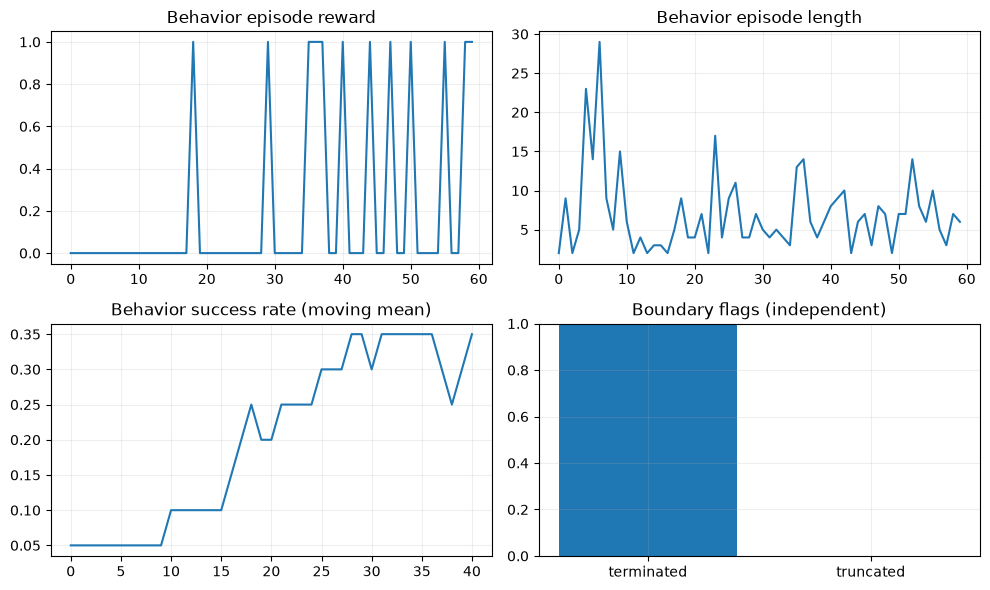

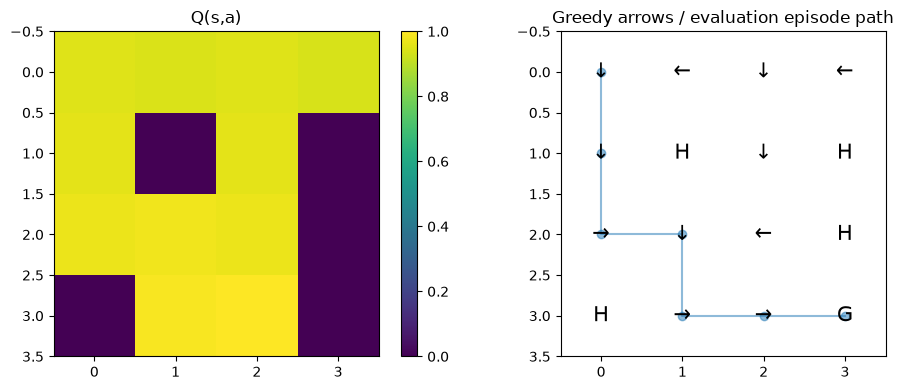

Q(s,a) [[0.9415 0.951  0.932  0.9415]
 [0.9415 0.     0.9414 0.932 ]
 [0.932  0.951  0.931  0.9413]
 [0.9406 0.     0.     0.9311]
 [0.951  0.9606 0.     0.9415]
 [0.     0.     0.     0.    ]
 [0.     0.9606 0.     0.9414]
 [0.     0.     0.     0.    ]
 [0.9606 0.     0.9703 0.951 ]
 [0.9606 0.9801 0.9606 0.    ]
 [0.9703 0.     0.     0.951 ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.9801 0.99   0.9627]
 [0.9801 0.99   1.     0.    ]
 [0.     0.     0.     0.    ]]
RESULT {"environment_steps": 421, "episodes": 60, "evaluation_mean_reward": 1.0, "evaluation_success": 1.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [5]:
model.eval()
evaluation = evaluate(eval_env, lambda state: model.act(state, deterministic=True).action.item(), episodes=5 if FAST else 100, seed=SEED+1000)
table = model.estimator.q_table.detach().cpu().numpy()
greedy_actions = table.argmax(-1)
summary = frozen_report(desc, log, table, evaluation, greedy_actions=greedy_actions, label='Q(s,a)')
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
실제 전이와 가상 전이가 같은 Learner/TargetGenerator/UpdateRule을 재사용한다. 관측 pair 모델과 planning 스케줄은 아직 examples 지원이며 Planner 클래스나 Learned World Model API는 없다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.